## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ryan Fang

**Date:** 10/12/2005

In [ ]:
# Your Phase 1 solution to the problem goes here.

# Q1:

In [9]:
# Q1 Part 1: Create the datasets
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    '0.125': df0_125,
    '0.25': df0_25,
    '0.5': df0_5,
    '1.0': df1_0,
    '2.0': df2_0
}

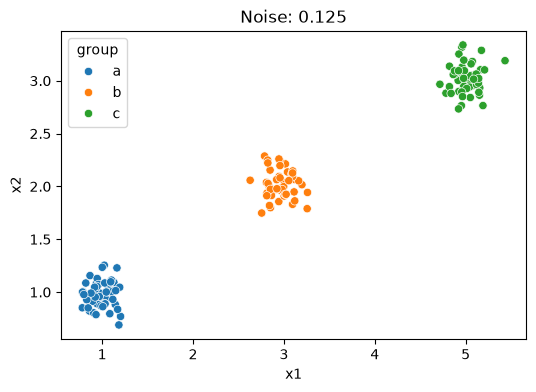

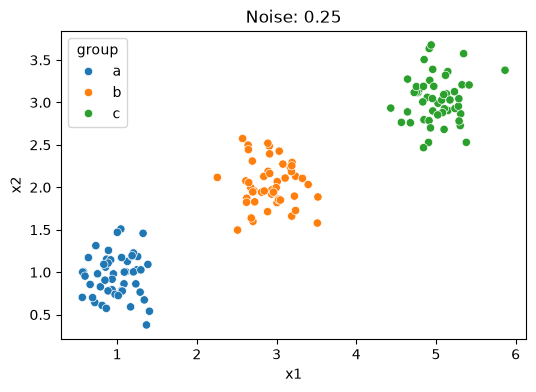

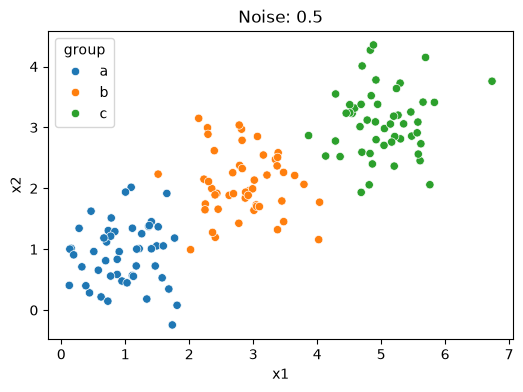

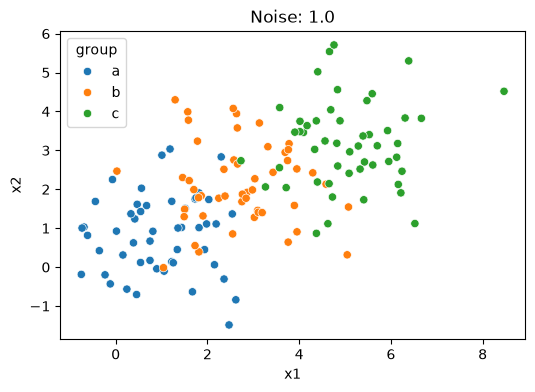

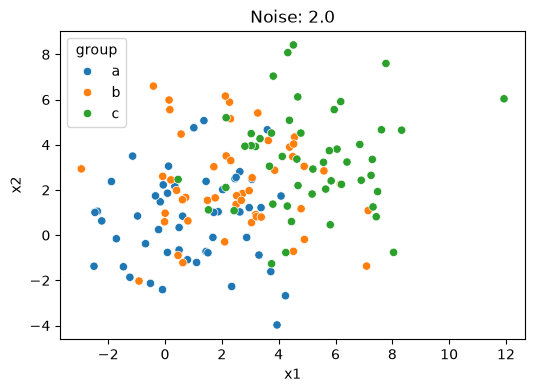

In [14]:
# Q1 Part 2: Make scatterplots of the (X1,X2) points by group

# Loop through each dataset and create a separate, full-sized scatterplot
for noise, df in datasets.items():
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=df, x="x1", y="x2", hue="group")
    plt.title(f"Noise: {noise}")
    plt.show()

**Q1 Part 2 Answer:**
As the `noise` level increases from 0.125 to 2.0, the visual distinctness of the clusters deteriorates significantly. At low noise levels (0.125 and 0.25), the groups 'a', 'b', and 'c' form tight, perfectly separated clusters. As noise reaches 1.0 and 2.0, the points spread out so much that the clusters overlap entirely, and it becomes very messy and super scattered.

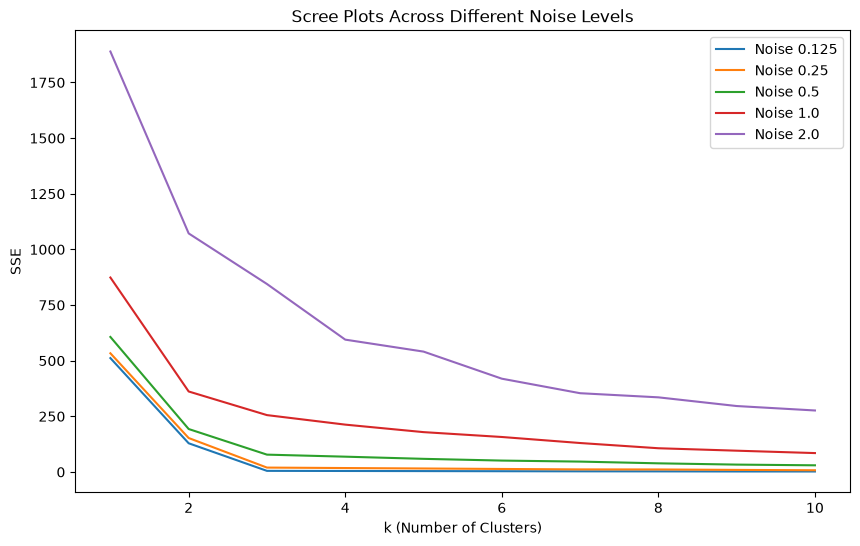

In [15]:
# Q1 Part 3: Create a scree plot for each of the datasets

# Create a single large canvas for all scree plots
plt.figure(figsize=(10, 6))
ks = np.arange(1, 11)

for noise, df in datasets.items():
    X = df[['x1', 'x2']]
    SSE = []
    
    # Calculate SSE for each k
    for k in ks:
        model = KMeans(n_clusters=k, n_init='auto', random_state=0).fit(X)
        SSE.append(model.inertia_)
        
    # Plot the line for this specific noise level
    sns.lineplot(x=ks, y=SSE, label=f"Noise {noise}")

plt.title("Scree Plots Across Different Noise Levels")
plt.xlabel("k (Number of Clusters)")
plt.ylabel("SSE")
plt.legend()
plt.show()

**Q1 Part 3 Answer:**
Increasing $k$ generally reduces the Sum of Squared Error (SSE). At low noise levels (0.125 and 0.25), the scree plots have a very clear elbow at $k=3$, which means that adding a 4th cluster reduces the SSE by a much smaller amount. As the noise level increases to 1.0 and 2.0, the elbow disappears, and the data varies continuously with no distinct groups. High noise severely limits the ability to clearly select $k$ because the elbow method does not always give a clear choice when boundaries are obscured.

**Q1 Part 4 Answer:** 
The intuition of the elbow comes from the fact that the total SSE is the sum of the squared distances from observations in each cluster to their respective centroids. Because choosing $k$ by SSE alone naturally favors too many clusters, we plot the models' SSE against $k$ to look some sort of an elbow. 

We saw in our examples of low-noise simulations that moving from 1 to 2 to 3 clusters drops the SSE drastically because we are correctly assigning the distinct true groups to their own centroids. However, moving from 3 to 4 clusters yields a much smaller reduction in SSE, creating the elbow shape. This tells us that beyond $k=3$, adding more clusters doesn't give us any new significant new patterns in the data.

# Q2:

In [21]:
# Q2 Part 1: Load data, filter, and clean
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

# 1. Load the dataset
df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")

# Filter for the year 2020
if 'Year' in df.columns:
    df_2020 = df[df['Year'] == 2020].copy()
else:
    df_2020 = df.copy()

# The numerical variables we need for the clustering analysis
features = [
    'Spending (2020 USD)', 
    'Spending per Capita', 
    'Percent of Government Spending', 
    'Percent of GDP'
]

# Strip units/separators, coerce to numeric, track missingness, etc
for var in features:
    if var in df_2020.columns:
        # Strip potential string artifacts like '$' or ',' or '%' before coercing
        if df_2020[var].dtype == 'object':
            cleaned_strings = df_2020[var].str.replace(r'[$,%]', '', regex=True)
            df_2020[f'{var}_clean'] = pd.to_numeric(cleaned_strings, errors='coerce')
        else:
            df_2020[f'{var}_clean'] = pd.to_numeric(df_2020[var], errors='coerce')
        
        df_2020[f'{var}_nan'] = df_2020[f'{var}_clean'].isnull()

clean_cols = [f'{var}_clean' for var in features if var in df_2020.columns]
df_model = df_2020.dropna(subset=clean_cols).copy()

print(f"Number of countries after dropping missing values: {len(df_model)}")

Number of countries after dropping missing values: 148


**Q2 Part 1 Answer:**
Yes, further cleaning is required before just dropping rows. As taught in the slides, numeric-looking values often hide units (like `$`), separators (like `,`), or nonnumeric codes. If we don't strip those out first, `pd.to_numeric` will turn perfectly good data into missing values. We must strip those characters, use `errors='coerce'` to handle whatever is left, and explicitly track what was coerced using a `_nan` indicator column so we don't silently overwrite the original data.

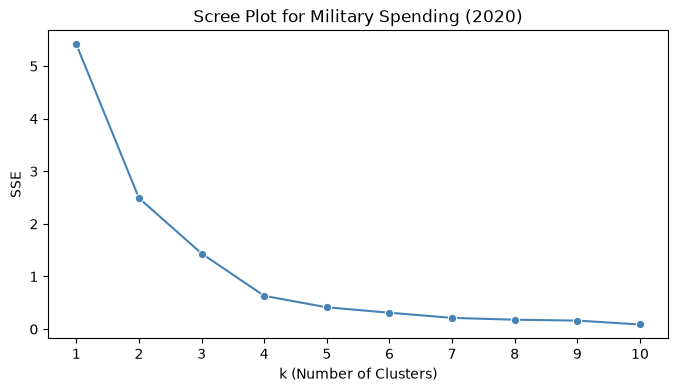

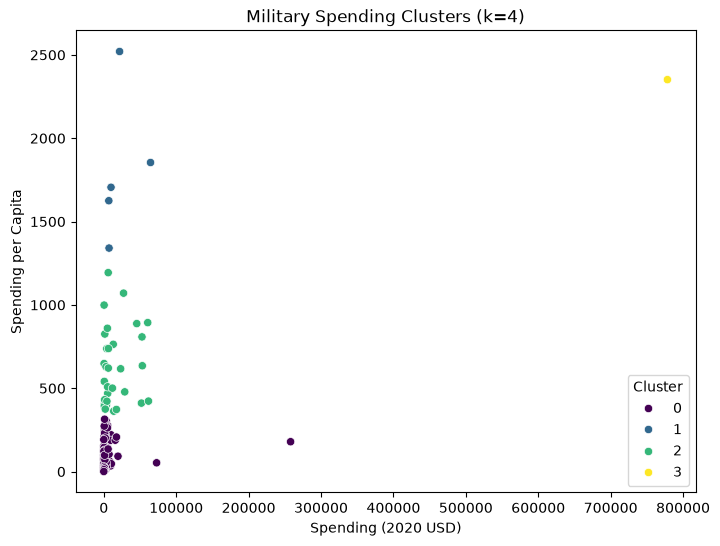

Cluster Summary Statistics:


Spending (2020 USD)_clean                                  \
                               count       mean       std        min   
cluster_p2                                                             
0                              111.0    4859.19  25405.74       8.62   
1                                5.0   22112.89  24492.09    6941.04   
2                               31.0   16723.34  20332.99     405.79   
3                                1.0  778397.20       NaN  778397.20   

                                                        \
                  25%        50%        75%        max   
cluster_p2                                               
0              130.01     382.46    2297.03  257973.43   
1             7269.88    9978.57   21816.57   64558.40   
2             2540.89    6095.71   25291.11   61712.54   
3           778397.20  778397.20  778397.20  778397.20   

           Spending per Capita_clean                                     \
                               count     mean     std      min      25%   
cluster_p2                                                                
0                              111.0    80.06   83.50     0.58    14.88   
1                                5.0  1809.35  439.20  1341.06  1625.16   
2                               31.0   626.39  229.07   362.47   422.43   
3                                1.0  2351.63     NaN  2351.63  2351.63   

                                       
                50%      75%      max  
cluster_p2                             
0             47.06   125.39   314.20  
1           1705.74  1854.38  2520.40  
2            616.85   785.89  1193.60  
3           2351.63  2351.63  2351.63


United States Cluster Membership:


,Country,cluster_p2,Spending (2020 USD)_clean,Spending per Capita_clean
5540,United States of America,3,778397.2,2351.631858


In [23]:
# Q2 Part 2: Max-min normalize, scree plot, and clustering

# Max-min normalize the two specific features
features_p2 = ['Spending (2020 USD)_clean', 'Spending per Capita_clean']
X_p2 = df_model[features_p2]

scaler = MinMaxScaler()
X_p2_scaled = pd.DataFrame(
    scaler.fit_transform(X_p2), 
    columns=features_p2, 
    index=df_model.index
)

# Create a scree plot to determine the optimal k
ks = np.arange(1, 11)
SSE = []

for k in ks:
    model = KMeans(n_clusters=k, n_init='auto', random_state=42)
    model.fit(X_p2_scaled)
    SSE.append(model.inertia_)

plt.figure(figsize=(8, 4))
sns.lineplot(x=ks, y=SSE, marker='o', color='steelblue')
plt.title('Scree Plot for Military Spending (2020)')
plt.xlabel('k (Number of Clusters)')
plt.ylabel('SSE')
plt.xticks(ks)
plt.grid(False)
plt.show()

# Based on the scree plot elbow, select the optimal k
optimal_k = 4

# K-means clustering and Scatter plot
kmeans = KMeans(n_clusters=optimal_k, n_init='auto', random_state=42)
df_model['cluster_p2'] = kmeans.fit_predict(X_p2_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_model, 
    x='Spending (2020 USD)_clean', 
    y='Spending per Capita_clean', 
    hue='cluster_p2', 
    palette='viridis'
)
plt.title(f'Military Spending Clusters (k={optimal_k})')
plt.xlabel('Spending (2020 USD)')
plt.ylabel('Spending per Capita')
plt.legend(title='Cluster')
plt.show()

# Compute describe table conditional on cluster membership
print("Cluster Summary Statistics:")
cluster_stats = df_model.groupby('cluster_p2')[features_p2].describe().round(2)
display(cluster_stats)

# Find where the United States is located
if 'Country' in df_model.columns:
    us_data = df_model[df_model['Country'].str.contains('United States', na=False, case=False)]
    print("\nUnited States Cluster Membership:")
    display(us_data[['Country', 'cluster_p2'] + features_p2])

**Q2 Part 2 Answer:**

Looking at the scree plot, the sharpest "elbow" where the SSE stops dropping drastically is at $k=4$. The scatter plot and summary statistics show heavy right-skewness. Most countries cluster tightly in the bottom-left corner of the graph which means there is low total spending and low per capita spending. A second small cluster represents countries with very high per capita spending but moderate total spending. Looking at the graph still, we can find that the US stands alone in the very top right of the chart as its own cluster. It is a massive outlier due to the extremely high total spending and high spending per capita compared to the rest of the world. 

I can see that the the clustering algorithm separates the vast majority of normal-spending nations from the extreme outliers. It isolates massive global superpowers based on their total spending volume, and wealthy/smaller nations based on per capita intensity.

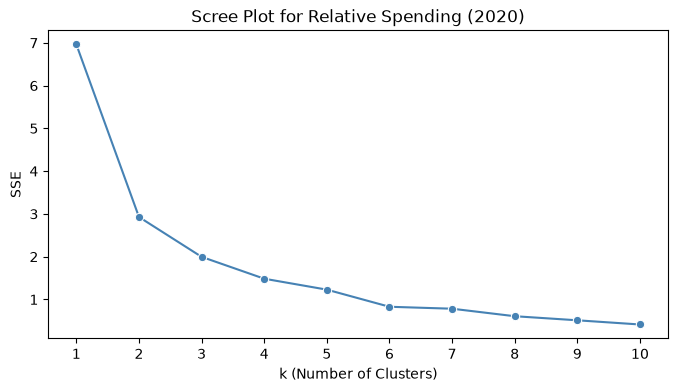

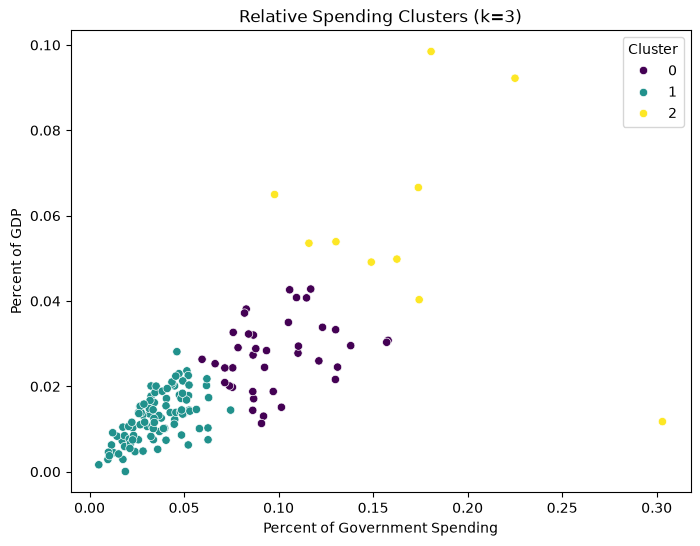

Cluster Summary Statistics (Relative Spending):


Percent of Government Spending_clean                                \
                                          count  mean   std   min   25%   50%   
cluster_p3                                                                      
0                                          39.0  0.10  0.02  0.06  0.08  0.09   
1                                          99.0  0.04  0.01  0.00  0.03  0.03   
2                                          10.0  0.17  0.06  0.10  0.14  0.17   

                       Percent of GDP_clean                                \
             75%   max                count  mean   std   min   25%   50%   
cluster_p3                                                                  
0           0.11  0.16                 39.0  0.03  0.01  0.01  0.02  0.03   
1           0.05  0.07                 99.0  0.01  0.01  0.00  0.01  0.01   
2           0.18  0.30                 10.0  0.06  0.02  0.01  0.05  0.05   

                        
             75%   max  
cluster_p3              
0           0.03  0.04  
1           0.02  0.03  
2           0.07  0.10


United States Cluster Membership (Relative Spending):


,Country,cluster_p3,Percent of Government Spending_clean,Percent of GDP_clean
5540,United States of America,0,0.081976,0.037179


In [27]:
# Q2 Part 3: Clustering on Percent of Government Spending and Percent of GDP

# Isolate and Max-Min Normalize the relative spending features
features_p3 = ['Percent of Government Spending_clean', 'Percent of GDP_clean']
X_p3 = df_model[features_p3]

scaler3 = MinMaxScaler()
X_p3_scaled = pd.DataFrame(
    scaler3.fit_transform(X_p3), 
    columns=features_p3, 
    index=df_model.index
)

# Scree plot to determine the optimal k
ks = np.arange(1, 11)
SSE3 = []

for k in ks:
    model = KMeans(n_clusters=k, n_init='auto', random_state=42)
    model.fit(X_p3_scaled)
    SSE3.append(model.inertia_)

plt.figure(figsize=(8, 4))
sns.lineplot(x=ks, y=SSE3, marker='o', color='steelblue')
plt.title('Scree Plot for Relative Spending (2020)')
plt.xlabel('k (Number of Clusters)')
plt.ylabel('SSE')
plt.xticks(ks)
plt.show()

# Selecting k based on the elbow 
optimal_k3 = 3

# K-means clustering and Scatter plot
kmeans3 = KMeans(n_clusters=optimal_k3, n_init='auto', random_state=42)
df_model['cluster_p3'] = kmeans3.fit_predict(X_p3_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_model, 
    x='Percent of Government Spending_clean', 
    y='Percent of GDP_clean', 
    hue='cluster_p3', 
    palette='viridis'
)
plt.title(f'Relative Spending Clusters (k={optimal_k3})')
plt.xlabel('Percent of Government Spending')
plt.ylabel('Percent of GDP')
plt.legend(title='Cluster')
plt.show()

# Compute describe table conditional on cluster membership
print("Cluster Summary Statistics (Relative Spending):")
cluster_stats3 = df_model.groupby('cluster_p3')[features_p3].describe().round(2)
display(cluster_stats3)

# Find where the United States is located
if 'Country' in df_model.columns:
    us_data3 = df_model[df_model['Country'].str.contains('United States', na=False, case=False)]
    print("\nUnited States Cluster Membership (Relative Spending):")
    display(us_data3[['Country', 'cluster_p3'] + features_p3])

**Q2 Part 3 Answer:**

Compared to the previous part, clustering by absolute spending (`Spending USD` and `Spending per Capita`), the United States was a massive outlier sitting in a cluster almost entirely by itself due to its sheer wealth and spending volume. However, when clustering by relative spending (`Percent of Gov Spending` and `Percent of GDP`), the results change and the US is no longer an outlier. 

The clusters now represent the economic impact from spending on the military rather than absolute size. As mentioned, the US is no longer a standalone outlier; and, it falls into a cluster of countries that dedicate a moderately high percentage of their overall economy and government budget to the military. The extreme outliers in this plot are smaller nations carrying massive relative military burdens.

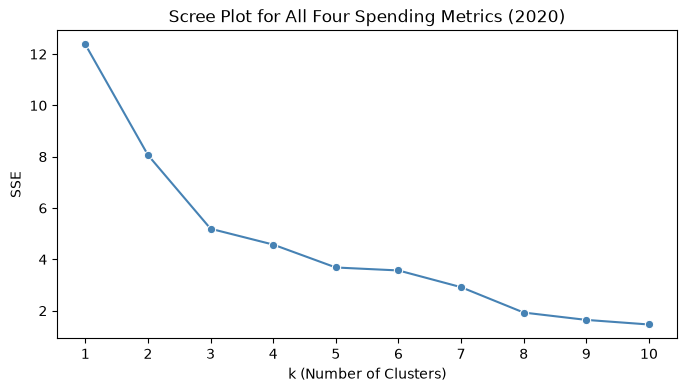

Cluster Summary Statistics (All Four Metrics):


Spending (2020 USD)_clean                                          \
                               count       mean        std      min      25%   
cluster_p4                                                                     
0                              112.0    7024.65   26367.95     8.62   130.56   
1                                6.0  147964.58  309635.19  6095.71  7700.42   
2                               30.0    9073.54   18135.03   163.93   522.74   

                                          Spending per Capita_clean           \
                 50%       75%        max                     count     mean   
cluster_p4                                                                     
0             539.07   3821.39  257973.43                     112.0   196.20   
1           15897.57  53872.94  778397.20                       6.0  1875.15   
2            1663.09   8646.65   72937.06                      30.0   215.92   

            ... Percent of Government Spending_clean        \
            ...                                  75%   max   
cluster_p4  ...                                              
0           ...                                 0.05  0.10   
1           ...                                 0.16  0.23   
2           ...                                 0.14  0.30   

           Percent of GDP_clean                                            
                          count  mean   std   min   25%   50%   75%   max  
cluster_p4                                                                 
0                         112.0  0.01  0.01  0.00  0.01  0.01  0.02  0.03  
1                           6.0  0.06  0.03  0.03  0.04  0.06  0.09  0.10  
2                          30.0  0.03  0.01  0.01  0.03  0.03  0.04  0.07  

[3 rows x 32 columns]


United States Cluster Membership (All Four Metrics):


,Country,cluster_p4,Spending (2020 USD)_clean,Spending per Capita_clean,Percent of Government Spending_clean,Percent of GDP_clean
5540,United States of America,1,778397.2,2351.631858,0.081976,0.037179


In [37]:
# Q2 Part 4: Clustering on all four numeric variables

# Combine all four features and normalize
features_p4 = features_p2 + features_p3
X_p4 = df_model[features_p4]

scaler4 = MinMaxScaler()
X_p4_scaled = pd.DataFrame(
    scaler4.fit_transform(X_p4), 
    columns=features_p4, 
    index=df_model.index
)

# 2. Scree plot for all four variables
SSE4 = []
for k in ks:
    model = KMeans(n_clusters=k, n_init='auto', random_state=42)
    model.fit(X_p4_scaled)
    SSE4.append(model.inertia_)

plt.figure(figsize=(8, 4))
sns.lineplot(x=ks, y=SSE4, marker='o', color='steelblue')
plt.title('Scree Plot for All Four Spending Metrics (2020)')
plt.xlabel('k (Number of Clusters)')
plt.ylabel('SSE')
plt.xticks(ks)
plt.show()

# Selecting k based on the elbow 
optimal_k4 = 3

# K-means clustering 
kmeans4 = KMeans(n_clusters=optimal_k4, n_init='auto', random_state=42)
df_model['cluster_p4'] = kmeans4.fit_predict(X_p4_scaled)

# Compute describe table conditional on cluster membership
print("Cluster Summary Statistics (All Four Metrics):")
cluster_stats4 = df_model.groupby('cluster_p4')[features_p4].describe().round(2)
display(cluster_stats4)

if 'Country' in df_model.columns:
    us_data4 = df_model[df_model['Country'].str.contains('United States', na=False, case=False)]
    print("\nUnited States Cluster Membership (All Four Metrics):")
    display(us_data4[['Country', 'cluster_p4'] + features_p4])

**Q2 Part 4 Answer:**

When we include all four variables, the $k$-Means algorithm is forced to balance absolute spending size with relative economic burden. We also can't make a 2d scatterplot as well. But looking at the table, we can see that absolute spending (`Spending 2020 USD`) is extremely skewed by the United States. That feature specifically impacts the distance calculations, even after normalization. Therefore, this means that the results tend to look a bit more like the Part 2 graph. The algorithm generally isolates the massive global superpower(s) into a small outlier cluster, while putting the rest of the world in their clusters based on their relative military burden.

**Q2 Part 5 Answer:**

Yes, I would say that the $k$-Means algorithm found very useful patterns. It successfully revealed two different ways to look at global military spending. 
1. It highlighted the difference between absolute military superpowers (like the US, which spends the most money) and high-burden military states that spend the highest proportion of their resources.
2. The algorithm effectively clustered the vast majority of the world into a "baseline" group of low-to-moderate absolute and relative spenders, allowing the geopolitical outliers to clearly stand out.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen. 

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]